# Lab 7: Healthcare Operations and Resource Optimization

**AI in Healthcare · Unit II · Student notebook · Approximately 120 minutes**  
**Companion lecture:** [Healthcare Operations and Resource Optimization](../lectures/session-07-healthcare-operations-resource-optimization.ipynb)

## Learning objectives

By the end of this lab, you should be able to:

1. Audit synthetic appointment requests and distinguish predictions from realized outcomes.
2. Trace a multi-clinician outpatient queue.
3. Calculate access, waiting, utilization, overtime, and urgent-delay measures.
4. Compare booking policies across repeated uncertain clinic days.
5. Test sensitivity to changing demand and model miscalibration.
6. Recommend a policy while stating safety, equity, and deployment limitations.

**Prerequisites:** Python, pandas, NumPy, descriptive statistics, and the companion lecture.  
**Dependencies:** Python 3, NumPy, pandas, and matplotlib. No downloads or installation cells are required.

All patient identifiers, probabilities, groups, events, and results in this notebook are deterministic synthetic teaching fixtures. The lab does not provide clinical advice or evidence that a policy is suitable for a real clinic.

> **Submission note:** all TODO cells are completed, and every output was produced by running this notebook top-to-bottom in a fresh kernel. The provided infrastructure functions are unchanged.

## Scenario and decision frame

You support a fictional outpatient clinic with two clinicians and an eight-hour day. The normal template contains 30 appointment places. The manager is considering:

- retaining the baseline template;
- reserving places for uncertain same-day urgent demand;
- adding limited bookings to slots whose scheduled patient has a high predicted non-attendance probability; or
- using non-preemptive urgency priority when selecting the next waiting patient.

The schedule must be created **before the clinic opens**. Predicted non-attendance probability is available then. Actual attendance, arrival delay, consultation duration, and urgent requests are future realizations and must not be used to construct the schedule.

| Item | Definition |
|---|---|
| Intended user | Clinic manager |
| Unit in `requests` | One appointment request |
| Unit in a simulated queue | One attended visit or urgent request |
| Decision time | Before clinic opening |
| Action | Choose reservation, overbooking, and queue rules |
| Main outcomes | Access, waiting, overtime, utilization, urgent delay, subgroup effects |

The clinic and its 30-minute urgent-wait review threshold are illustrative, not clinical standards.

## Deliverables and rubric

Submit the completed notebook with:

1. data audit and interpretation;
2. validated baseline queue trace;
3. policy-comparison table over repeated days;
4. at least two plots showing both typical and high-delay outcomes;
5. demand and calibration sensitivity results;
6. subgroup audit with sample sizes; and
7. a concise recommendation memo with assumptions and limitations.

| Criterion | Marks |
|---|---:|
| Data audit, row meaning, and decision-time reasoning | 15 |
| Queue trace and operational metrics | 20 |
| Reproducible repeated-policy comparison | 25 |
| Uncertainty and sensitivity analysis | 15 |
| Safety and subgroup evaluation | 15 |
| Interpretation, recommendation, and limitations | 10 |
| **Total** | **100** |

Code that runs is necessary but not sufficient. Marks depend on explaining what the outputs mean and what the simulation cannot establish.

## Setup and generate the fixture — 10 minutes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

CLINIC_CLOSE_MINUTE = 480  # 17:00 when minute 0 represents 09:00
BASE_TEMPLATE_SIZE = 30
N_CLINICIANS = 2
URGENT_WAIT_REVIEW_MIN = 30  # illustrative lab rule, not a clinical standard

In [2]:
def make_synthetic_requests(seed=7, n_requests=40):
    # Create fictional requests and scores available before the clinic day.
    rng = np.random.default_rng(seed)
    access_group = rng.choice(
        ["near_clinic", "far_from_clinic"],
        size=n_requests,
        p=[0.65, 0.35],
    )
    travel_minutes = np.where(
        access_group == "near_clinic",
        rng.integers(5, 31, n_requests),
        rng.integers(35, 91, n_requests),
    )
    prior_missed = rng.binomial(2, np.where(access_group == "near_clinic", 0.12, 0.22))
    raw_score = -2.8 + 0.018 * travel_minutes + 0.75 * prior_missed
    predicted_no_show = 1 / (1 + np.exp(-raw_score))

    requests = pd.DataFrame(
        {
            "request_id": [f"R{i:03d}" for i in range(n_requests)],
            "patient_id": [f"P{i:03d}" for i in range(n_requests)],
            "request_order": np.arange(1, n_requests + 1),
            "access_group": access_group,
            "travel_minutes": travel_minutes,
            "prior_missed_appointments": prior_missed,
            "predicted_no_show_probability": np.clip(predicted_no_show, 0.05, 0.60),
        }
    )
    return requests


requests = make_synthetic_requests()
requests.head()

,request_id,patient_id,request_order,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability
0,R000,P000,1,near_clinic,18,0,0.077558
1,R001,P001,2,far_from_clinic,68,1,0.304492
2,R002,P002,3,far_from_clinic,59,0,0.149567
3,R003,P003,4,near_clinic,27,0,0.089970
4,R004,P004,5,near_clinic,9,1,0.131473


The fixture is **hand-created synthetic data**, not an export from a clinical system. `access_group` exists to investigate whether a policy produces different outcomes; it is not a clinical urgency label.

The no-show score is generated partly from travel time and prior missed appointments. This deliberately creates an ethical issue: a scheduling rule may convert an access barrier into worse service for the people affected by it.

## Exercise 1: Audit appointment requests — 10 minutes

1. Confirm the row count and uniqueness of `request_id` and `patient_id`.
2. Check ranges and missingness.
3. Summarize request count and predicted non-attendance probability by `access_group`.
4. State whether `predicted_no_show_probability` is a prediction, decision, or observed outcome.
5. Explain why the eventual `showed_up` value must not appear in this table.

Complete the cell below. Preserve one row per appointment request.

In [3]:
print("Rows:", len(requests))
print("Unique request_id:", requests["request_id"].nunique(), "| unique patient_id:", requests["patient_id"].nunique())
print("\nMissing values per column:")
print(requests.isna().sum().to_string())
print("\nRanges of numeric columns:")
display(requests.select_dtypes("number").agg(["min", "max", "mean"]).round(3))

request_audit_by_group = (
    requests.groupby("access_group")
    .agg(requests=("request_id", "count"),
         share=("request_id", lambda s: len(s) / len(requests)),
         travel_min_mean=("travel_minutes", "mean"),
         prior_missed_mean=("prior_missed_appointments", "mean"),
         pred_no_show_mean=("predicted_no_show_probability", "mean"),
         pred_no_show_min=("predicted_no_show_probability", "min"),
         pred_no_show_max=("predicted_no_show_probability", "max"))
    .round(3)
)
# Requests that would be booked into the 30-place baseline template (first 30 by request order)
booked30 = requests.sort_values("request_order").head(BASE_TEMPLATE_SIZE)
request_audit_by_group["in_first_30"] = booked30.groupby("access_group").size()
request_audit_by_group

Rows: 40
Unique request_id: 40 | unique patient_id: 40

Missing values per column:
request_id                       0
patient_id                       0
request_order                    0
access_group                     0
travel_minutes                   0
prior_missed_appointments        0
predicted_no_show_probability    0

Ranges of numeric columns:


,request_order,travel_minutes,prior_missed_appointments,predicted_no_show_probability
min,1.0,6.000,0.000,0.063
max,40.0,89.000,1.000,0.320
mean,20.5,29.625,0.275,0.125


,requests,share,travel_min_mean,prior_missed_mean,pred_no_show_mean,pred_no_show_min,pred_no_show_max,in_first_30
access_group,,,,,,,,
far_from_clinic,11,0.275,62.818,0.273,0.198,0.117,0.320,9
near_clinic,29,0.725,17.034,0.276,0.097,0.063,0.171,21


In [4]:
assert requests["request_id"].is_unique, "request_id must be unique"
assert requests["patient_id"].is_unique, "This fixture expects one request per patient"
assert requests["predicted_no_show_probability"].between(0, 1).all()

if request_audit_by_group is None:
    print("Complete Exercise 1: create request_audit_by_group.")
else:
    display(request_audit_by_group)

,requests,share,travel_min_mean,prior_missed_mean,pred_no_show_mean,pred_no_show_min,pred_no_show_max,in_first_30
access_group,,,,,,,,
far_from_clinic,11,0.275,62.818,0.273,0.198,0.117,0.320,9
near_clinic,29,0.725,17.034,0.276,0.097,0.063,0.171,21


**Exercise 1 — audit findings**

1. **40 rows, 40 unique `request_id` and 40 unique `patient_id`**, so one row = one appointment request = one patient in this fixture.
2. **No missing values.** Ranges are plausible: travel 6–89 min, prior missed appointments 0–1 (the generator allows 2, but none occurred with this seed), and predicted no-show probability 0.063–0.320, all inside the [0.05, 0.60] clip.
3. **By group:** 29 near-clinic requests (72.5%) and 11 far-from-clinic (27.5%). The far group's mean predicted no-show is **0.198, about double the near group's 0.097**, even though prior-missed counts are almost identical (0.27 vs 0.28). The gap comes almost entirely from travel time (63 vs 17 min). 9 far and 21 near requests fall in the first 30 booked places.
4. `predicted_no_show_probability` is a **prediction**: a model's estimate made before the day. It is not a decision (the decision is the schedule built from it) and not an observed outcome.
5. `showed_up` is only known **after** the clinic day. If it appeared in this table, any schedule built from the table could use future information (leakage), and the evaluation would look better than anything achievable in practice. The schedule must be built from information available before opening; attendance is realised later by the simulation.

## Build schedules and simulate the queue

The following functions are provided infrastructure. Read their docstrings before using them.

`build_schedule` creates a decision using only pre-opening information. Reserving a place reduces routine bookings. Score-guided overbooking assigns additional requests to times associated with the highest predicted non-attendance probabilities; it does not deny the original patient an appointment.

In [5]:
def build_schedule(
    request_table,
    reserve_slots=0,
    overbook_slots=0,
    score_guided_overbooking=False,
    base_template_size=BASE_TEMPLATE_SIZE,
):
    # Create a pre-opening schedule without using realized attendance.
    if reserve_slots < 0 or overbook_slots < 0:
        raise ValueError("reserve_slots and overbook_slots must be non-negative")
    regular_places = base_template_size - reserve_slots
    if regular_places <= 0:
        raise ValueError("reserve_slots leave no routine appointment places")
    if regular_places + overbook_slots > len(request_table):
        raise ValueError("Not enough appointment requests for this policy")

    template = np.repeat(np.arange(0, 450, 30), 2)
    if reserve_slots:
        # Spread nominal reserved capacity across the day instead of simply
        # removing the final appointments. Same-day arrivals still join the queue.
        reserved_positions = np.floor(
            (np.arange(reserve_slots) + 0.5) * len(template) / reserve_slots
        ).astype(int)
        regular_template = np.delete(template, reserved_positions)
    else:
        regular_template = template
    selected = request_table.sort_values("request_order").head(regular_places).copy()
    selected["scheduled_minute"] = regular_template[:regular_places]
    selected["booking_type"] = "standard"

    if overbook_slots:
        waitlist = (
            request_table.sort_values("request_order")
            .iloc[regular_places : regular_places + overbook_slots]
            .copy()
        )
        if score_guided_overbooking:
            host_slots = selected.nlargest(
                overbook_slots, "predicted_no_show_probability"
            )["scheduled_minute"].to_numpy()
        else:
            host_slots = selected.tail(overbook_slots)["scheduled_minute"].to_numpy()
        waitlist["scheduled_minute"] = host_slots
        waitlist["booking_type"] = "overbooked"
        selected = pd.concat([selected, waitlist], ignore_index=True)

    return selected.sort_values(
        ["scheduled_minute", "booking_type", "request_order"], kind="stable"
    ).reset_index(drop=True)


baseline_schedule = build_schedule(requests)
baseline_schedule[[
    "request_id",
    "patient_id",
    "scheduled_minute",
    "booking_type",
    "predicted_no_show_probability",
]].head(8)

,request_id,patient_id,scheduled_minute,booking_type,predicted_no_show_probability
0,R000,P000,0,standard,0.077558
1,R001,P001,0,standard,0.304492
2,R002,P002,30,standard,0.149567
3,R003,P003,30,standard,0.089970
4,R004,P004,60,standard,0.131473
5,R005,P005,60,standard,0.319950
6,R006,P006,90,standard,0.092961
7,R007,P007,90,standard,0.116500


In [6]:
def process_queue(arrivals, n_clinicians=N_CLINICIANS, queue_rule="fcfs"):
    # Run a non-preemptive multi-clinician queue. FCFS selects the
    # longest-waiting arrival; urgent_priority selects urgent visits first,
    # then by arrival. A consultation in progress is never interrupted.
    if queue_rule not in {"fcfs", "urgent_priority"}:
        raise ValueError("queue_rule must be 'fcfs' or 'urgent_priority'")
    if n_clinicians < 1:
        raise ValueError("n_clinicians must be at least 1")

    pending = arrivals.sort_values("arrival_minute", kind="stable").reset_index(drop=True)
    server_available = np.zeros(n_clinicians, dtype=float)
    waiting = []
    records = []
    next_arrival_index = 0
    current_time = 0.0

    while next_arrival_index < len(pending) or waiting:
        if not waiting:
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

        while (
            next_arrival_index < len(pending)
            and pending.loc[next_arrival_index, "arrival_minute"] <= current_time
        ):
            waiting.append(pending.loc[next_arrival_index].to_dict())
            next_arrival_index += 1

        free_servers = np.flatnonzero(server_available <= current_time)
        while waiting and len(free_servers):
            if queue_rule == "urgent_priority":
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (
                        0 if waiting[i]["urgency"] == "urgent" else 1,
                        waiting[i]["arrival_minute"],
                        waiting[i]["visit_id"],
                    ),
                )
            else:
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (waiting[i]["arrival_minute"], waiting[i]["visit_id"]),
                )

            visit = waiting.pop(chosen_index)
            server = int(free_servers[0])
            start = current_time
            finish = start + float(visit["service_duration_min"])
            records.append(
                {
                    **visit,
                    "clinician": server + 1,
                    "service_start_minute": start,
                    "completion_minute": finish,
                    "wait_min": start - float(visit["arrival_minute"]),
                }
            )
            server_available[server] = finish
            free_servers = np.flatnonzero(server_available <= current_time)

        if waiting:
            current_time = float(server_available.min())
        elif next_arrival_index < len(pending):
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

    return pd.DataFrame(records).sort_values(
        ["service_start_minute", "clinician"], kind="stable"
    ).reset_index(drop=True)


def simulate_clinic_day(
    schedule,
    seed,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Realize attendance and demand, then process one fictional clinic day.
    # no_show_logit_shift changes actual non-attendance odds while leaving the
    # pre-opening predicted probabilities unchanged. It supports a drift test.
    # Independent streams keep urgent demand and shared patient outcomes aligned
    # when the same seed is used to compare policies of different sizes.
    streams = np.random.SeedSequence(seed).spawn(6)
    attendance_rng, arrival_rng, service_rng, urgent_count_rng, urgent_arrival_rng, urgent_service_rng = [
        np.random.default_rng(stream) for stream in streams
    ]
    regular = schedule.copy()
    predicted = regular["predicted_no_show_probability"].to_numpy()
    predicted_logit = np.log(predicted / (1 - predicted))
    actual_no_show_probability = 1 / (
        1 + np.exp(-(predicted_logit + no_show_logit_shift))
    )
    showed_up = attendance_rng.random(len(regular)) >= actual_no_show_probability

    attended = regular.loc[showed_up].copy()
    attended["visit_id"] = "V-" + attended["request_id"]
    attended["source"] = "scheduled"
    attended["urgency"] = "routine"
    attended["arrival_minute"] = np.maximum(
        0,
        attended["scheduled_minute"].to_numpy()
        + arrival_rng.normal(0, 8, len(attended)),
    )
    attended["service_duration_min"] = np.clip(
        service_rng.lognormal(np.log(24), 0.35, len(attended)), 8, 60
    )

    urgent_count = urgent_count_rng.poisson(urgent_rate)
    urgent = pd.DataFrame(
        {
            "visit_id": [f"U-{seed}-{i}" for i in range(urgent_count)],
            "request_id": pd.NA,
            "patient_id": [f"UP-{seed}-{i}" for i in range(urgent_count)],
            "request_order": pd.NA,
            "access_group": "not_recorded_for_urgent_fixture",
            "travel_minutes": np.nan,
            "prior_missed_appointments": np.nan,
            "predicted_no_show_probability": np.nan,
            "scheduled_minute": np.nan,
            "booking_type": "same_day_request",
            "source": "same_day",
            "urgency": "urgent",
            "arrival_minute": urgent_arrival_rng.uniform(0, 420, urgent_count),
            "service_duration_min": np.clip(
                urgent_service_rng.lognormal(np.log(30), 0.35, urgent_count), 10, 75
            ),
        }
    )

    arrivals = pd.concat([attended, urgent], ignore_index=True, sort=False)
    return process_queue(arrivals, n_clinicians=n_clinicians, queue_rule=queue_rule)

### Validate the queue engine

Before trusting a complex simulation, test a deterministic case whose answer can be calculated by hand. The assertions below expect waits of 0, 15, and 10 minutes for one clinician.

In [7]:
toy_arrivals = pd.DataFrame(
    {
        "visit_id": ["P1", "P2", "P3"],
        "patient_id": ["P1", "P2", "P3"],
        "source": ["scheduled"] * 3,
        "urgency": ["routine"] * 3,
        "access_group": ["toy"] * 3,
        "arrival_minute": [0.0, 5.0, 25.0],
        "service_duration_min": [20.0, 15.0, 10.0],
    }
)
toy_result = process_queue(toy_arrivals, n_clinicians=1, queue_rule="fcfs")

assert toy_result["wait_min"].tolist() == [0.0, 15.0, 10.0]
assert toy_result["completion_minute"].tolist() == [20.0, 35.0, 45.0]
print("Deterministic FCFS check passed.")
toy_result[[
    "visit_id", "arrival_minute", "service_start_minute",
    "completion_minute", "wait_min"
]]

Deterministic FCFS check passed.


,visit_id,arrival_minute,service_start_minute,completion_minute,wait_min
0,P1,0.0,0.0,20.0,0.0
1,P2,5.0,20.0,35.0,15.0
2,P3,25.0,35.0,45.0,10.0


## Exercise 2: Trace one baseline clinic day — 15 minutes

1. Simulate seed `2026` using `baseline_schedule` and FCFS.
2. Check that waits and service durations are non-negative.
3. Display the five longest waits.
4. Explain why `len(day)` is the number of attended/same-day visits, not the number of scheduled appointments or unique requests.
5. Plot a clinician timeline using horizontal bars. Use different colours for routine and urgent visits.

Visits processed (attended + same-day): 32 | scheduled appointments: 30 | no-shows: 2 | urgent same-day: 4


,visit_id,urgency,access_group,scheduled_minute,arrival_minute,service_start_minute,wait_min,clinician
22,V-R020,routine,near_clinic,300.0,299.4,322.9,23.5,1
29,U-2026-2,urgent,not_recorded_for_urgent_fixture,NaN,391.1,407.5,16.4,2
7,V-R006,routine,near_clinic,90.0,93.0,108.9,15.8,2
13,V-R013,routine,near_clinic,180.0,175.5,189.3,13.8,2
12,V-R012,routine,near_clinic,180.0,161.9,174.4,12.5,2


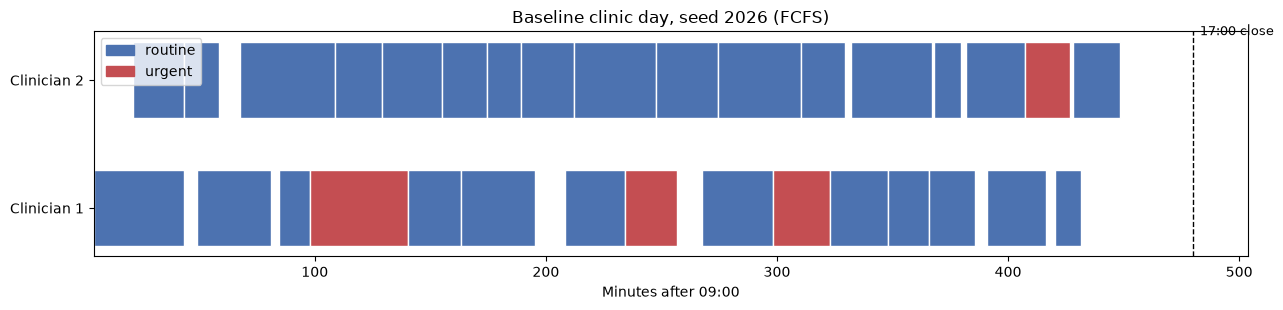

In [8]:
baseline_day = simulate_clinic_day(
    baseline_schedule,
    seed=2026,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
)

assert (baseline_day["wait_min"] >= 0).all()
assert (baseline_day["service_duration_min"] > 0).all()

print("Visits processed (attended + same-day):", len(baseline_day),
      "| scheduled appointments:", len(baseline_schedule),
      "| no-shows:", len(baseline_schedule) - (baseline_day.source == "scheduled").sum(),
      "| urgent same-day:", (baseline_day.source == "same_day").sum())
display(baseline_day.nlargest(5, "wait_min")[[
    "visit_id", "urgency", "access_group", "scheduled_minute", "arrival_minute",
    "service_start_minute", "wait_min", "clinician"]].round(1))

fig, ax = plt.subplots(figsize=(13, 3.2))
colours = {"routine": "#4C72B0", "urgent": "#C44E52"}
for row in baseline_day.itertuples():
    ax.barh(row.clinician, row.service_duration_min, left=row.service_start_minute,
            color=colours[row.urgency], edgecolor="white", height=0.6)
ax.axvline(CLINIC_CLOSE_MINUTE, color="k", ls="--", lw=1)
ax.text(CLINIC_CLOSE_MINUTE + 3, 2.35, "17:00 close", fontsize=9)
ax.set_yticks([1, 2], ["Clinician 1", "Clinician 2"])
ax.set_xlabel("Minutes after 09:00")
ax.set_title("Baseline clinic day, seed 2026 (FCFS)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colours.items()], loc="upper left")
plt.tight_layout(); plt.show()

**Exercise 2 — interpretation.** Seed 2026 produced **32 visits**: 30 scheduled − 2 no-shows + 4 urgent same-day arrivals. `len(day)` counts *processed visits*. No-shows never enter the queue, while urgent arrivals add rows that were never scheduled requests, so it equals neither the number of appointments (30) nor the number of unique requests (40). The longest wait was 23.5 min (a routine patient at minute 300, arriving when both clinicians were busy). One urgent patient waited 16.4 min. In the timeline, clinicians are busy for most of the day with short idle gaps, and both finish before 17:00 (no overtime on this day). This is one random day, so the repeated simulation below is needed before drawing conclusions.

## Exercise 3: Calculate operational outcomes — 20 minutes

Implement `summarise_day`. Return a dictionary containing at least:

- `visits`
- `started_by_close`
- `mean_wait_min`
- `median_wait_min`
- `p90_wait_min`
- `max_wait_min`
- `utilization_before_close`
- `overtime_min`
- `urgent_visits`
- `urgent_wait_breaches`

For utilization, count only the part of each consultation falling between minute 0 and minute 480:

$$
\text{busy before close}=
\sum_i \max(0,\min(f_i,480)-\max(s_i,0)),
$$

then divide by `n_clinicians × 480`. Here $s_i$ and $f_i$ are visit $i$'s service start and finish.

In [9]:
def summarise_day(
    visits,
    n_clinicians=N_CLINICIANS,
    closing_minute=CLINIC_CLOSE_MINUTE,
    urgent_wait_review_min=URGENT_WAIT_REVIEW_MIN,
):
    """Operational metrics for one simulated day (one row per processed visit)."""
    start = visits["service_start_minute"].to_numpy(dtype=float)
    finish = visits["completion_minute"].to_numpy(dtype=float)
    wait = visits["wait_min"].to_numpy(dtype=float)
    urgent = visits["urgency"].eq("urgent").to_numpy()

    # Busy minutes falling inside the staffed window [0, closing_minute]
    busy_before_close = np.clip(np.minimum(finish, closing_minute) - np.maximum(start, 0), 0, None).sum()
    last_finish = finish.max() if len(finish) else 0.0

    return {
        "visits": int(len(visits)),
        "started_by_close": int((start < closing_minute).sum()),
        "mean_wait_min": float(wait.mean()),
        "median_wait_min": float(np.median(wait)),
        "p90_wait_min": float(np.quantile(wait, 0.90)),
        "max_wait_min": float(wait.max()),
        "utilization_before_close": float(busy_before_close / (n_clinicians * closing_minute)),
        "overtime_min": float(max(0.0, last_finish - closing_minute)),
        "urgent_visits": int(urgent.sum()),
        "urgent_wait_breaches": int((wait[urgent] > urgent_wait_review_min).sum()),
        "urgent_mean_wait_min": float(wait[urgent].mean()) if urgent.any() else np.nan,
        "routine_mean_wait_min": float(wait[~urgent].mean()) if (~urgent).any() else np.nan,
    }


baseline_metrics = summarise_day(baseline_day)
if baseline_metrics is None:
    print("Complete summarise_day to see the baseline metrics.")
else:
    display(pd.Series(baseline_metrics, name="baseline_seed_2026").round(2))

visits                      32.00
started_by_close            32.00
mean_wait_min                5.49
median_wait_min              3.03
p90_wait_min                13.66
max_wait_min                23.50
utilization_before_close     0.83
overtime_min                 0.00
urgent_visits                4.00
urgent_wait_breaches         0.00
urgent_mean_wait_min        10.25
routine_mean_wait_min        4.81
Name: baseline_seed_2026, dtype: float64

**Design notes:** *overtime* = minutes from 17:00 until the last consultation ends (0 if the clinic finishes early), so it measures the clinic day overrunning, not each clinician separately. An urgent *breach* is a wait strictly greater than 30 minutes. I also return mean waits split by urgent and routine visits, because the urgent-priority policy is expected to move waiting from one group to the other.

### Metric checks

Use checks as debugging aids, not as substitutes for interpretation. The utilization definition above should remain between 0 and 1 because it counts only busy time inside the staffed window. Overtime is reported separately.

In [10]:
if baseline_metrics is not None:
    required_metrics = {
        "visits", "started_by_close", "mean_wait_min", "median_wait_min",
        "p90_wait_min", "max_wait_min", "utilization_before_close",
        "overtime_min", "urgent_visits", "urgent_wait_breaches",
    }
    assert required_metrics.issubset(baseline_metrics)
    assert 0 <= baseline_metrics["utilization_before_close"] <= 1
    assert baseline_metrics["mean_wait_min"] <= baseline_metrics["max_wait_min"]
    assert baseline_metrics["urgent_wait_breaches"] <= baseline_metrics["urgent_visits"]
    print("Metric checks passed.")
else:
    print("Metric checks skipped until summarise_day is completed.")

Metric checks passed.


## Exercise 4: Compare scheduling policies — 25 minutes

The candidate policies below change one or more decisions:

- **Baseline:** 30 standard bookings, FCFS.
- **Reserve two:** 28 standard bookings, leaving nominal capacity for same-day demand.
- **Score-guided overbook two:** 30 standard plus two additional requests assigned to high predicted no-show slots.
- **Urgent priority:** baseline bookings with non-preemptive priority for urgent arrivals.

First inspect schedule counts and duplicate slot times. Then run every policy for at least 200 days. Use the same simulation seeds for each policy so that comparisons are not driven merely by different random-number sequences.

In [11]:
policy_definitions = {
    "baseline_fcfs": {
        "schedule": build_schedule(requests),
        "queue_rule": "fcfs",
    },
    "reserve_2_fcfs": {
        "schedule": build_schedule(requests, reserve_slots=2),
        "queue_rule": "fcfs",
    },
    "overbook_2_score_guided": {
        "schedule": build_schedule(
            requests,
            overbook_slots=2,
            score_guided_overbooking=True,
        ),
        "queue_rule": "fcfs",
    },
    "baseline_urgent_priority": {
        "schedule": build_schedule(requests),
        "queue_rule": "urgent_priority",
    },
}

pd.DataFrame(
    [
        {
            "policy": name,
            "scheduled_requests": len(spec["schedule"]),
            "overbooked_requests": (spec["schedule"]["booking_type"] == "overbooked").sum(),
            "queue_rule": spec["queue_rule"],
        }
        for name, spec in policy_definitions.items()
    ]
)

,policy,scheduled_requests,overbooked_requests,queue_rule
0,baseline_fcfs,30,0,fcfs
1,reserve_2_fcfs,28,0,fcfs
2,overbook_2_score_guided,32,2,fcfs
3,baseline_urgent_priority,30,0,urgent_priority


In [12]:
def evaluate_policy(
    policy_name,
    policy_spec,
    seeds,
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Run one policy repeatedly after summarise_day has been implemented.
    rows = []
    for simulation_id, seed in enumerate(seeds):
        visits = simulate_clinic_day(
            policy_spec["schedule"],
            seed=int(seed),
            n_clinicians=N_CLINICIANS,
            queue_rule=policy_spec["queue_rule"],
            urgent_rate=urgent_rate,
            no_show_logit_shift=no_show_logit_shift,
        )
        metrics = summarise_day(visits)
        if metrics is None:
            return None
        rows.append(
            {
                "policy": policy_name,
                "simulation_id": simulation_id,
                "seed": int(seed),
                **metrics,
            }
        )
    return pd.DataFrame(rows)


simulation_seeds = np.arange(20_000, 20_300)

# TODO: call evaluate_policy for every policy, concatenate the returned frames,
# and store the result in `policy_results`.
policy_results = pd.concat(
    [evaluate_policy(name, spec, simulation_seeds) for name, spec in policy_definitions.items()],
    ignore_index=True)
print("Rows:", len(policy_results), "=", policy_results.policy.nunique(), "policies x", len(simulation_seeds), "days")

if policy_results is None:
    print("Complete Exercise 4 to create policy_results.")
else:
    display(policy_results.head())

Rows: 1200 = 4 policies x 300 days


,policy,simulation_id,seed,visits,started_by_close,mean_wait_min,median_wait_min,p90_wait_min,max_wait_min,utilization_before_close,overtime_min,urgent_visits,urgent_wait_breaches,urgent_mean_wait_min,routine_mean_wait_min
0,baseline_fcfs,0,20000,29,29,15.469978,11.692476,41.693754,50.725742,0.830711,21.238276,4,0,9.316614,16.454516
1,baseline_fcfs,1,20001,32,32,45.474626,48.382525,71.871553,79.630140,0.909293,7.837575,5,3,39.504195,46.580261
2,baseline_fcfs,2,20002,34,31,47.884402,52.050501,83.488674,92.687510,0.940117,47.131275,6,4,33.383112,50.991821
3,baseline_fcfs,3,20003,34,33,31.546786,34.763482,56.888098,62.448676,0.954530,30.023058,7,2,18.506960,34.927482
4,baseline_fcfs,4,20004,30,30,6.392889,1.606919,17.131960,30.184471,0.807960,0.000000,2,0,5.554017,6.452808


Create a policy summary with:

- median visits and started-by-close count;
- median mean wait;
- median and 90th percentile of daily `p90_wait_min`;
- median utilization;
- 90th-percentile overtime; and
- mean urgent-wait breaches.

Then plot at least `mean_wait_min` and `overtime_min` distributions by policy. Explain why reporting only the mean across all simulations would be insufficient.

,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_daily_p90_wait,median_utilization,median_overtime,p90_overtime,share_days_overtime_gt_30,mean_urgent_breaches,mean_urgent_wait,mean_routine_wait
policy,,,,,,,,,,,,
baseline_fcfs,30.0,30.0,9.98,25.61,53.52,0.82,0.0,20.93,0.07,0.82,14.23,12.89
reserve_2_fcfs,28.0,28.0,7.77,21.54,46.19,0.78,0.0,9.57,0.03,0.55,11.30,9.94
overbook_2_score_guided,32.0,32.0,11.65,29.03,61.93,0.87,0.0,37.13,0.14,0.98,17.44,15.53
baseline_urgent_priority,30.0,30.0,10.00,26.58,60.48,0.82,0.0,21.00,0.06,0.05,6.73,14.62


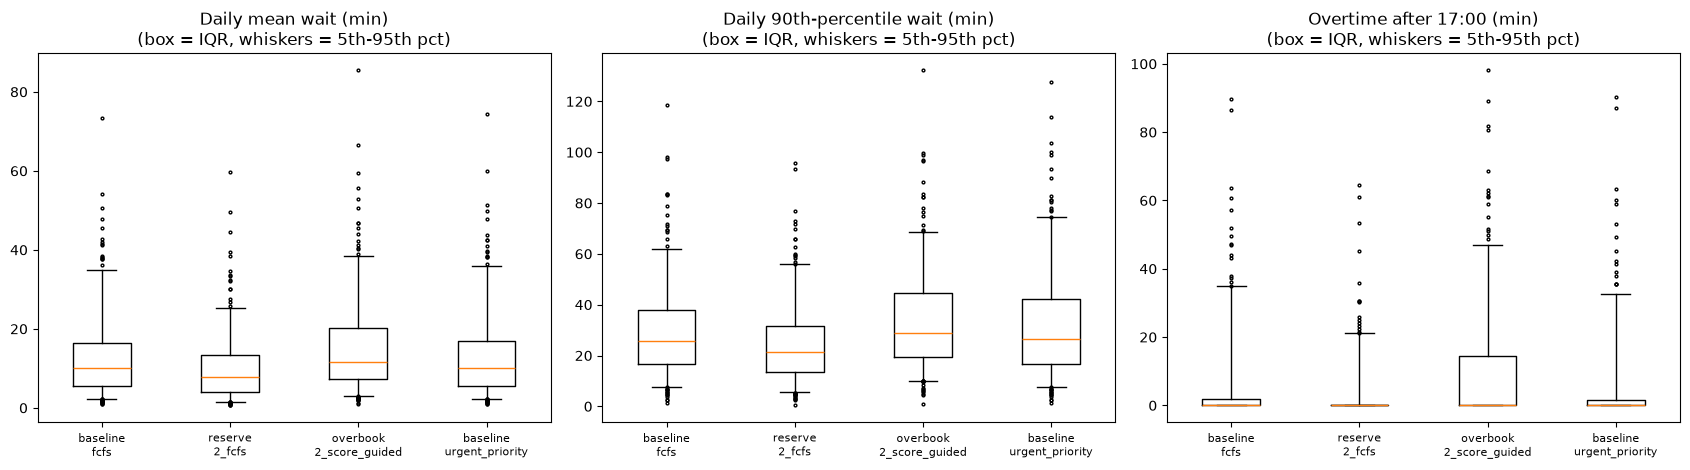

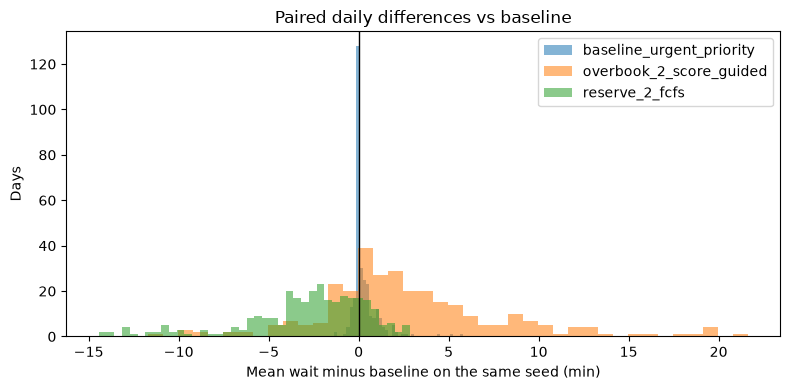

policy,baseline_urgent_priority,overbook_2_score_guided,reserve_2_fcfs
count,300.00,300.00,300.00
mean,0.29,2.67,-2.92
std,0.75,5.10,3.48
min,-1.40,-11.70,-14.45
10%,-0.22,-2.17,-7.33
50%,0.00,1.73,-2.31
90%,1.05,9.23,0.68
max,5.79,21.61,2.86


In [13]:
def summarise_policies(results):
    g = results.groupby("policy", sort=False)
    return pd.DataFrame({
        "median_visits": g["visits"].median(),
        "median_started_by_close": g["started_by_close"].median(),
        "median_mean_wait": g["mean_wait_min"].median(),
        "median_p90_wait": g["p90_wait_min"].median(),
        "p90_of_daily_p90_wait": g["p90_wait_min"].quantile(0.90),
        "median_utilization": g["utilization_before_close"].median(),
        "median_overtime": g["overtime_min"].median(),
        "p90_overtime": g["overtime_min"].quantile(0.90),
        "share_days_overtime_gt_30": g["overtime_min"].apply(lambda s: (s > 30).mean()),
        "mean_urgent_breaches": g["urgent_wait_breaches"].mean(),
        "mean_urgent_wait": g["urgent_mean_wait_min"].mean(),
        "mean_routine_wait": g["routine_mean_wait_min"].mean(),
    }).round(2)

policy_summary = summarise_policies(policy_results)

if policy_summary is None:
    print("Create policy_summary after policy_results is available.")
else:
    display(policy_summary)

order = list(policy_definitions)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, metric, label in zip(axes, ["mean_wait_min", "p90_wait_min", "overtime_min"],
                             ["Daily mean wait (min)", "Daily 90th-percentile wait (min)", "Overtime after 17:00 (min)"]):
    data = [policy_results.loc[policy_results.policy == p, metric] for p in order]
    ax.boxplot(data, whis=(5, 95), showfliers=True, flierprops={"markersize": 2})
    ax.set_xticks(range(1, len(order) + 1), [p.replace("_", "\n", 1) for p in order], fontsize=8)
    ax.set_title(label + "\n(box = IQR, whiskers = 5th-95th pct)")
plt.tight_layout(); plt.show()

# Paired comparison: the same seed = the same patients/urgent demand under each policy
paired = policy_results.pivot(index="seed", columns="policy", values="mean_wait_min")
diffs = paired.sub(paired["baseline_fcfs"], axis=0).drop(columns="baseline_fcfs")
fig, ax = plt.subplots(figsize=(8, 4))
for p in diffs:
    ax.hist(diffs[p], bins=40, alpha=0.55, label=p)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="Mean wait minus baseline on the same seed (min)", ylabel="Days", title="Paired daily differences vs baseline")
ax.legend(); plt.tight_layout(); plt.show()
display(diffs.describe(percentiles=[0.1, 0.5, 0.9]).round(2))

### My answers to the interpretation prompts (300 paired days per policy)

1. **Access:** score-guided overbooking starts the most visits before close (median **32** vs 30 for baseline/urgent-priority and 28 for reserve-2). Reserve-2 sees two fewer routine patients per day by design.
2. **Lowest tail waiting and overtime:** **reserve-2**. The 90th percentile of daily p90 wait is 46 min (baseline 54, overbook 62, urgent-priority 60), 90th-percentile overtime is 9.6 min (baseline 20.9, overbook 37.1), and only 3% of days run >30 min over (overbook: 14%). It gets these results partly by **serving fewer routine patients**, not by any real efficiency gain.
3. **Urgent priority** cuts mean urgent-wait breaches (>30 min) from **0.82 to 0.05 per day** and mean urgent wait from 14.2 to 6.7 min. The cost falls on routine patients: mean routine wait rises from 12.9 to 14.6 min and the routine tail lengthens (p90-of-p90 54 → 60 min). Total throughput and overtime are unchanged, because it only reorders the same work.
4. **No policy dominates.** Overbooking wins on access but loses on waiting and overtime. Reserve-2 wins on waiting and overtime but loses on access. Urgent priority wins on urgent safety but shifts delay onto routine patients. The paired differences confirm this: on the same seeds, reserve-2 lowers the daily mean wait on most days (median −2.3 min), and overbooking raises it (median +1.7, 90th pct +9.2 min).
5. **Constraints, not weights:** urgent-wait breaches (a safety constraint, e.g. ≈0 per day), overtime tail (a staff-wellbeing constraint, e.g. p90 ≤ 30 min) and subgroup disparity should be **hard limits**. Visits/access and mean wait can then be optimised among the policies that pass. Folding safety into a weighted score would let a large access gain "buy" urgent delays.

**Why the mean across all simulations is insufficient:** waiting and overtime are right-skewed (see the boxplots' long upper whiskers). A policy can have an acceptable average while 1 day in 10 has 60+ minute waits or 40+ minutes of overtime. Those bad days drive patient harm and staff burnout, so I report medians, 90th percentiles and the share of days above a limit.

### Interpretation prompts

1. Which policy completes or starts the most visits before closing?
2. Which policy has the lowest tail waiting and overtime?
3. Does urgent priority improve urgent-delay outcomes? What happens to routine waiting?
4. Does any policy dominate every other policy, or are there trade-offs?
5. Which measures would you treat as constraints rather than components of a weighted score?

## Exercise 5: Stress-test assumptions — 15 minutes

Policies should not be selected using only one assumed future. Repeat the policy comparison under:

1. **Demand surge:** set `urgent_rate=7.0`.
2. **Attendance drift:** set `no_show_logit_shift=-0.6`. This makes actual non-attendance less likely than the unchanged predictions suggest.

Store the two summaries as `surge_summary` and `attendance_drift_summary`. Identify any policy whose apparent advantage disappears or whose safety/workload outcomes worsen materially.

Explain why this is a policy stress test rather than external clinical validation.

Demand-surge summary ready: True
Attendance-drift summary ready: True


median_visits  median_mean_wait  p90_of_daily_p90_wait  \
scenario                      policy                                                                             
base                          baseline_fcfs                      30.0              9.98                  53.52   
                              reserve_2_fcfs                     28.0              7.77                  46.19   
                              overbook_2_score_guided            32.0             11.65                  61.93   
                              baseline_urgent_priority           30.0             10.00                  60.48   
surge (urgent_rate=7)         baseline_fcfs                      33.0             19.61                  86.65   
                              reserve_2_fcfs                     31.0             15.30                  74.12   
                              overbook_2_score_guided            35.0             23.25                  96.14   
                              baseline_urgent_priority           33.0             20.55                 105.62   
attendance drift (shift=-0.6) baseline_fcfs                      32.0             11.62                  61.21   
                              reserve_2_fcfs                     30.0              8.83                  49.95   
                              overbook_2_score_guided            33.0             15.08                  67.55   
                              baseline_urgent_priority           32.0             11.62                  69.23   

                                                        p90_overtime  mean_urgent_breaches  mean_urgent_wait  \
scenario                      policy                                                                           
base                          baseline_fcfs                    20.93                  0.82             14.23   
                              reserve_2_fcfs                    9.57                  0.55             11.30   
                              overbook_2_score_guided          37.13                  0.98             17.44   
                              baseline_urgent_priority         21.00                  0.05              6.73   
surge (urgent_rate=7)         baseline_fcfs                    62.90                  2.67             24.84   
                              reserve_2_fcfs                   43.26                  2.08             20.02   
                              overbook_2_score_guided          80.92                  3.14             29.78   
                              baseline_urgent_priority         60.18                  0.20              8.84   
attendance drift (shift=-0.6) baseline_fcfs                    31.28                  0.90             16.12   
                              reserve_2_fcfs                   15.37                  0.66             12.75   
                              overbook_2_score_guided          44.01                  1.21             20.12   
                              baseline_urgent_priority         30.69                  0.06              7.28   

                                                        mean_routine_wait  
scenario                      policy                                       
base                          baseline_fcfs                         12.89  
                              reserve_2_fcfs                         9.94  
                              overbook_2_score_guided               15.53  
                              baseline_urgent_priority              14.62  
surge (urgent_rate=7)         baseline_fcfs                         24.62  
                              reserve_2_fcfs                        19.43  
                              overbook_2_score_guided               29.13  
                              baseline_urgent_priority              30.94  
attendance drift (shift=-0.6) baseline_fcfs                         15.12  
                              reserve_2_fcfs          

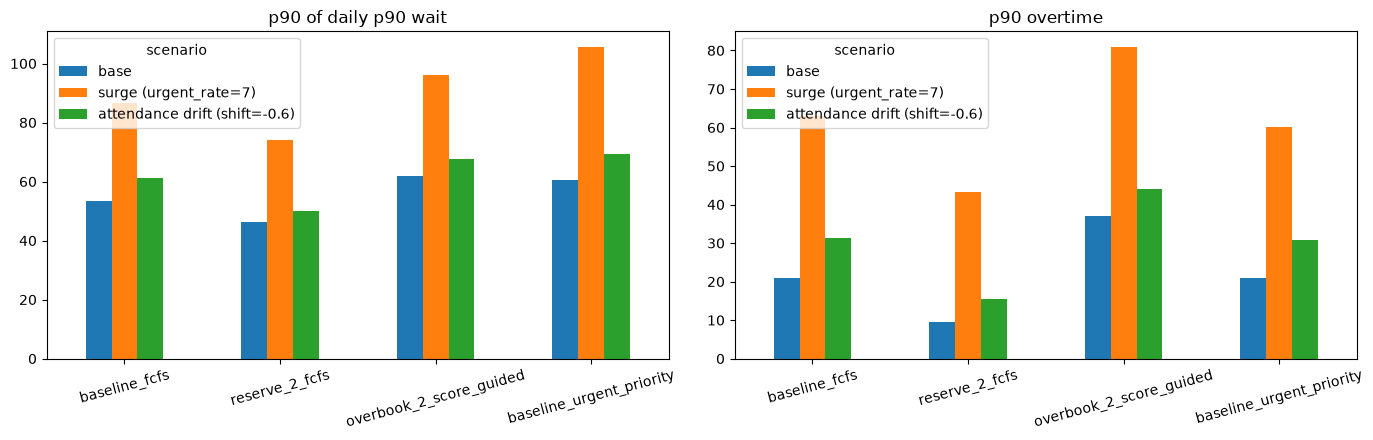

In [14]:
surge_results = pd.concat(
    [evaluate_policy(n, s, simulation_seeds, urgent_rate=7.0) for n, s in policy_definitions.items()],
    ignore_index=True)
surge_summary = summarise_policies(surge_results)

attendance_drift_results = pd.concat(
    [evaluate_policy(n, s, simulation_seeds, no_show_logit_shift=-0.6) for n, s in policy_definitions.items()],
    ignore_index=True)
attendance_drift_summary = summarise_policies(attendance_drift_results)

print("Demand-surge summary ready:", surge_summary is not None)
print("Attendance-drift summary ready:", attendance_drift_summary is not None)

key_cols = ["median_visits", "median_mean_wait", "p90_of_daily_p90_wait", "p90_overtime",
            "mean_urgent_breaches", "mean_urgent_wait", "mean_routine_wait"]
stress = pd.concat({"base": policy_summary[key_cols], "surge (urgent_rate=7)": surge_summary[key_cols],
                    "attendance drift (shift=-0.6)": attendance_drift_summary[key_cols]}, names=["scenario"])
display(stress)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["p90_of_daily_p90_wait", "p90_overtime"]):
    stress[metric].unstack("scenario").loc[order].plot.bar(ax=ax, rot=15)
    ax.set_title(metric.replace("_", " ")); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Exercise 5 — stress-test findings**

- **Demand surge (7 urgent/day instead of 4):** every policy deteriorates sharply (baseline p90 overtime 21 → 63 min, mean wait 10 → 20 min). **Urgent priority keeps urgent breaches near zero (0.20/day vs 2.67 for baseline)**, so its safety advantage *grows* under surge. Its cost to routine patients also grows: mean routine wait is 30.9 min, the worst of all policies, and the routine tail is the longest (p90-of-p90 106 min). Overbooking becomes the worst on overtime (p90 81 min).
- **Attendance drift (shift −0.6, more patients attend than predicted):** the score-guided overbooking assumes the high-score slots will often be empty. When patients attend more often than predicted, both patients in a double-booked slot show up more often: overbooking's p90 overtime rises to 44 min and urgent breaches to 1.21/day, the worst of all. Its access advantage shrinks to +1 visit over baseline (33 vs 32), because baseline also gains visits. **Overbooking's apparent advantage largely disappears under miscalibration, while its harms grow.** Reserve-2 stays the most robust on waiting and overtime under both stresses.

**Why this is a stress test, not external validation:** all scenarios come from the same hand-built simulator, with its own assumptions about service-time distributions, punctuality, Poisson urgent demand, no breaks and two interchangeable clinicians. We only changed two parameters inside it. External validation would need real outcome data from a different clinic or time period, compared against what the model predicted. The stress test shows which conclusions are *fragile* to assumptions. It cannot show that any conclusion holds in reality.

## Exercise 6: Audit subgroup effects — 15 minutes

The score partly reflects travel time, so score-guided overbooking may affect the two synthetic access groups differently.

For the score-guided policy:

1. Count standard and overbooked requests by `access_group`.
2. Across at least 200 simulated days, calculate attended sample size, mean wait, and 90th-percentile wait by group.
3. Compare those results with the baseline.
4. Report sample sizes beside every subgroup measure.
5. Explain why an observed difference is a reason to investigate, not proof of discrimination or harm.

Do not treat missing `access_group` for synthetic urgent arrivals as one of the scheduled-patient groups.

In [15]:
score_schedule = policy_definitions["overbook_2_score_guided"]["schedule"]
booking_audit_by_group = (score_schedule.groupby(["access_group", "booking_type"]).size()
                          .unstack(fill_value=0))
booking_audit_by_group["total"] = booking_audit_by_group.sum(axis=1)

# Which patients' slots received the extra bookings (the 'hosts')?
overbooked_minutes = score_schedule.loc[score_schedule.booking_type == "overbooked", "scheduled_minute"]
hosts = (score_schedule.loc[(score_schedule.booking_type == "standard") &
                            score_schedule.scheduled_minute.isin(overbooked_minutes)]
         .nlargest(len(overbooked_minutes), "predicted_no_show_probability"))
booking_audit_by_group["slots_double_booked_as_host"] = hosts.groupby("access_group").size()
booking_audit_by_group = booking_audit_by_group.fillna(0).astype(int)


def subgroup_waits(policy_name, seeds=simulation_seeds):
    spec = policy_definitions[policy_name]
    rows = []
    for seed in seeds:
        day = simulate_clinic_day(spec["schedule"], seed=int(seed), queue_rule=spec["queue_rule"])
        rows.append(day.loc[day.source == "scheduled", ["access_group", "wait_min"]])  # exclude urgent fixture rows
    pooled = pd.concat(rows, ignore_index=True)
    return pooled.groupby("access_group")["wait_min"].agg(
        attended_visits_n="size", mean_wait="mean", p90_wait=lambda s: s.quantile(0.9),
        share_wait_gt_30=lambda s: (s > 30).mean())

subgroup_results = pd.concat({p: subgroup_waits(p) for p in ["baseline_fcfs", "overbook_2_score_guided"]},
                             names=["policy"]).round(2)
subgroup_results["attended_per_day"] = (subgroup_results["attended_visits_n"] / len(simulation_seeds)).round(2)

if booking_audit_by_group is None:
    print("Create booking_audit_by_group.")
else:
    display(booking_audit_by_group)

if subgroup_results is None:
    print("Create subgroup_results with sample sizes and waiting measures.")
else:
    display(subgroup_results)
    print("Change vs baseline (score-guided minus baseline):")
    display((subgroup_results.loc["overbook_2_score_guided"] - subgroup_results.loc["baseline_fcfs"]).round(2))
display(hosts[["patient_id", "access_group", "travel_minutes", "prior_missed_appointments",
               "predicted_no_show_probability", "scheduled_minute"]])

booking_type,overbooked,standard,total,slots_double_booked_as_host
access_group,,,,
far_from_clinic,0,9,9,2
near_clinic,2,21,23,0


attended_visits_n  mean_wait  p90_wait  share_wait_gt_30  attended_per_day
policy                  access_group                                                                               
baseline_fcfs           far_from_clinic               2149      11.20     34.11              0.13              7.16
                        near_clinic                   5710      13.79     39.58              0.17             19.03
overbook_2_score_guided far_from_clinic               2118      14.02     41.40              0.17              7.06
                        near_clinic                   6252      16.32     45.28              0.20             20.84

Change vs baseline (score-guided minus baseline):


,attended_visits_n,mean_wait,p90_wait,share_wait_gt_30,attended_per_day
access_group,,,,,
far_from_clinic,-31,2.82,7.29,0.04,-0.10
near_clinic,542,2.53,5.70,0.03,1.81


,patient_id,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability,scheduled_minute
6,P005,far_from_clinic,72,1,0.31995,60
29,P027,far_from_clinic,72,1,0.31995,390


**Exercise 6 — subgroup audit**

- **Booking audit:** the 2 overbooked requests themselves are both near-clinic patients. **Both host slots that get double-booked belong to far-from-clinic patients** (P005 and P027, each 72 min travel and 1 prior missed appointment, predicted no-show 0.32). The no-show score is driven by travel time, so the policy targets the slots of people who face access barriers.
- **Repeated-day results (300 days, scheduled visits only; urgent fixture rows excluded):** under overbooking, the far group's mean wait rises from 11.2 to 14.0 min (+2.8) and its p90 wait from 34.1 to 41.4 min (**+7.3**). The near group's rises +2.5 (mean) and +5.7 (p90). The far group therefore bears a slightly larger tail increase. Sample sizes are 2,118–2,149 attended far-group visits (~7 per day) versus 5,710–6,252 near-group visits (~19–21 per day).
- In the base scenario, the far group had *lower* waits than the near group, so overbooking does not create a gap where none existed. However, it concentrates the extra double-booking burden on the far group's slots. In a real clinic, a far-travelling patient who arrives at a double-booked slot after a 72-minute journey and then waits longer may be more likely to miss future appointments, reinforcing the score.

**Why this is a reason to investigate, not proof of harm:** the far group has only 11 synthetic patients (9 booked), the difference of a few minutes comes from one simulator with arbitrary assumptions, the 300 simulated days re-use the *same* 30 patients so they are not independent people, and wait time is only one dimension of harm. The pattern justifies monitoring wait times by access group in a pilot, and asking whether the score should use travel time at all. It does not establish discrimination.

## Exercise 7: Recommendation memo — 10 minutes

Write 150–250 words addressed to the fictional clinic manager. Include:

1. the policy you recommend for a limited pilot—or why none should be piloted;
2. evidence from access, tail waiting, overtime, and urgent-delay outcomes;
3. what happened under demand and attendance stress tests;
4. any subgroup concern and its sample size;
5. an override or escalation mechanism;
6. three measures to monitor; and
7. one important limitation of the synthetic model.

Do not describe the selected policy as clinically validated or ready for autonomous deployment.

**Your memo:**

**To:** Clinic manager · **Re:** Booking and queue policy pilot (synthetic simulation)

I recommend a **limited pilot of non-preemptive urgent priority**, keeping the baseline 30-place template. Across 300 simulated days it reduced urgent waits over 30 minutes from 0.82 to 0.05 per day, with the same throughput (median 30 visits) and the same overtime (p90 ≈ 21 min). The cost is about +1.7 minutes of mean routine wait and a longer routine tail (p90 of daily p90 wait 54 → 60 min). Under a demand surge (7 urgent/day) it still kept urgent breaches near zero (0.20/day), but routine waits roughly doubled (mean 31 min), so surge days need extra cover.

I do **not** recommend score-guided overbooking. It adds two visits, but has the worst tail waits and overtime (p90 37 min, rising to 44 min when attendance is better than predicted), and both double-booked slots belong to far-travelling patients (n = 9 booked far-group patients; ~7 attended per day). Reserve-2 had the best waits and overtime, but costs two routine appointments per day. It is a reasonable second option if access is less constrained than staff time.

**Override:** staff may serve a routine patient first when that patient's wait exceeds 45 minutes or there is clinical concern, and any clinician can escalate an "urgent" label.
**Monitor:** urgent waits over 30 min, routine p90 wait by access group, and daily overtime.
**Key limitation:** the simulator assumes two interchangeable clinicians, no breaks, and synthetic arrival and service times. These results are not clinically validated and the policy should not run unsupervised.

## Reflection questions

1. Why can average daily workload be below nominal capacity while patients still wait?
2. What information was available at scheduling time, and what was realized later?
3. Why might optimizing only utilization produce an undesirable policy?
4. How does non-preemptive urgent priority differ from interrupting a consultation?
5. What operational features are absent from this simulation—rooms, breaks, staff roles, or something else—and which omission matters most?
6. How would deployment change the future data used to retrain a no-show model?
7. What evidence would be required before applying this approach in a real clinic?

## Optional extensions

- Add a lunch break or temporary clinician absence.
- Add a room constraint separate from clinician availability.
- Compare three-clinician staffing with two-clinician overtime.
- Calculate confidence intervals across simulated days.
- Replace the supplied score with a leakage-safe model trained on synthetic historical days.
- Formulate a small constrained grid search that rejects policies exceeding an urgent-delay or overtime limit.

## Reproducibility note

The notebook creates all data in memory and writes no files. Rerunning from a fresh kernel reproduces the fixture and simulation seeds. Changing the generator or policy assumptions changes the teaching results; record any such changes in your submission.

### My answers to the reflection questions

1. **Average workload below capacity, yet patients wait.** Median utilisation is ~0.82, but arrivals and consultation lengths are random. Patients cluster (two booked per slot, late or early arrivals, urgent arrivals at random times) and some consultations run long, so queues form during busy spells while idle time in quiet spells cannot be stored and used later. Queueing delay rises steeply as utilisation approaches 1, even when the average is below it.
2. **Known at scheduling vs realised later.** Known before opening: the request list and order, travel time, prior missed appointments, predicted no-show probability, the template and the policy. Realised later: who actually attends, arrival times (punctuality), consultation durations, and the number and timing of urgent requests.
3. **Optimising only utilisation** rewards packing the day (e.g. heavy overbooking). That keeps clinicians busy but creates long tail waits, overtime, urgent delays and unequal burden on the patients whose slots are double-booked. Overbooking had the highest utilisation (0.87) and the worst waits and overtime.
4. **Non-preemptive vs interrupting.** Here an urgent patient goes to the front of the *waiting line* but must wait for the current consultation to finish. A preemptive rule would stop an ongoing consultation, which is unsafe and impractical clinically, and wastes the partial work done. This is why urgent waits are reduced to ~7 min on average rather than to zero.
5. **Missing features:** rooms and equipment, lunch breaks, staff roles (nurse triage, admin), clinician absence, multi-visit patients, patients who leave without being seen, variable urgency levels and appointment types, and same-day routine requests. **Breaks and clinician absence** probably matter most: losing a clinician for even an hour removes a large share of a two-clinician clinic's capacity and would dominate the tail outcomes.
6. **Deployment changes future data (feedback loop).** If high-score patients are double-booked and then wait longer, they may miss more future appointments. Their no-show labels then rise, which confirms and strengthens the score in retraining. Also, outcomes are only observed under the deployed policy, so retraining learns from data the policy itself shaped. Policy-aware evaluation and monitoring by subgroup are needed.
7. **Evidence before real use:** validation of the simulator against the clinic's own historical data (arrival, service and no-show distributions); calibration and subgroup performance of the no-show model on local data; a prospective, staff-supervised pilot with predefined safety stop rules (urgent delays, overtime, subgroup waits); patient and staff feedback; and an equity review of using travel-related features.